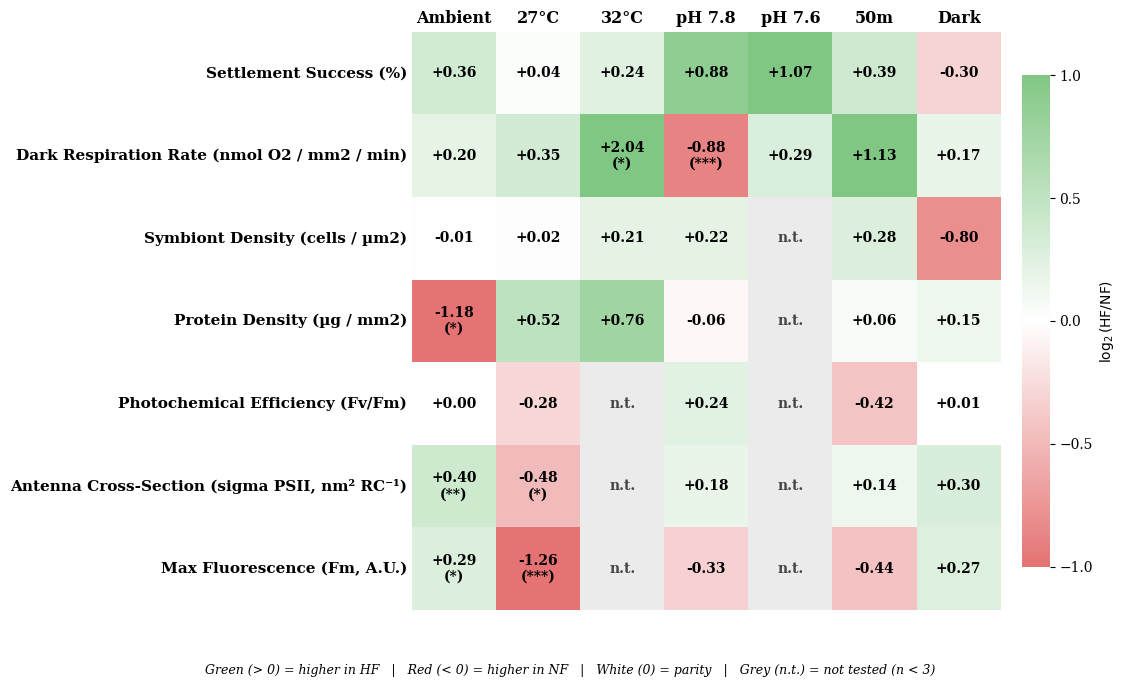

In [4]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MultipleLocator
import seaborn as sns

# ==============================================================================
# 1. CONFIGURATION
# ==============================================================================
SCALE_MODE = "log2FC"   # "log2FC" -> log2(HF/NF) | "index" -> (HF-NF)/(HF+NF)
OUT_STEM = "PhenotypeEffect"

PHYS_SUMMARY_CSV = "Spat_standardized_table_s4.csv"
FIRE_SUMMARY_CSV = "FIRe_TableS4_Summary.csv"

TREATMENT_ORDER = ["Ambient", "27°C", "32°C", "pH 7.8", "pH 7.6", "50m", "Dark"]

TARGET_METRICS = {
    "settlement":       "Settlement Success (%)",
    "respiration":      "Dark Respiration Rate (nmol O2 / mm2 / min)",
    "symbiont_density": "Symbiont Density (cells / µm2)",
    "protein_density":  "Protein Density (µg / mm2)",
    "FvFm":             "Photochemical Efficiency (Fv/Fm)",
    "Sigma":            "Antenna Cross-Section (sigma PSII, nm² RC⁻¹)",
    "Fm":               "Max Fluorescence (Fm, A.U.)",
}

plt.rcParams.update({
    "font.family": "serif",
    "axes.edgecolor": "black",
    "axes.linewidth": 1.2,
    "text.color": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "savefig.dpi": 600,
})

CMAP = LinearSegmentedColormap.from_list(
    "morph_advantage", ["#e57373", "#ffffff", "#81c784"], N=256
)

# ==============================================================================
# 2. LOAD & NORMALIZE BOTH STATISTICAL SUMMARY CSVs BEFORE CONCATENATING
# ==============================================================================
def standardize_summary_df(path):
    df = pd.read_csv(path)
    col_map = {
        "Metric / Parameter": "Metric",
        "Condition / Treatment": "Condition",
        "HF_Value": "HF_Summary",
        "NF_Value": "NF_Summary",
        "Sig": "Significance",
    }
    df = df.rename(columns={k: v for k, v in col_map.items() if k in df.columns})
    df = df.loc[:, ~df.columns.duplicated()].copy()
    return df


def extract_mean(val):
    """Extract the leading numeric Mean from 'Mean ± SD [med: Median]' or float."""
    if pd.isna(val):
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    s = str(val).strip()
    if s.upper() in {"N/A", "NAN", "N.T.", "N.A.", "-", ""}:
        return np.nan
    match = re.match(r"^([+-]?\d*\.?\d+(?:[eE][+-]?\d+)?)", s)
    return float(match.group(1)) if match else np.nan


def map_metric_name(raw_name):
    s = str(raw_name).strip().lower()
    if "settlement" in s:
        return "settlement"
    if "respiration" in s or "oxy" in s:
        return "respiration"
    if "symbiont" in s or "cell" in s:
        return "symbiont_density"
    if "protein" in s:
        return "protein_density"
    if "fv/fm" in s or "fvfm" in s:
        return "FvFm"
    if "sigma" in s or "σpsii" in s:
        return "Sigma"
    if s.startswith("fm"):
        return "Fm"
    return None


df_phys = standardize_summary_df(PHYS_SUMMARY_CSV)
df_fire = standardize_summary_df(FIRE_SUMMARY_CSV)
combined_df = pd.concat([df_phys, df_fire], ignore_index=True)

combined_df["Condition"] = (
    combined_df["Condition"]
    .astype(str)
    .str.replace(r"\s*\n.*", "", regex=True)
    .str.split("(").str[0]
    .str.strip()
)
combined_df["Canonical_Metric"] = combined_df["Metric"].apply(map_metric_name)
combined_df["HF_Mean"] = combined_df["HF_Summary"].apply(extract_mean)
combined_df["NF_Mean"] = combined_df["NF_Summary"].apply(extract_mean)

combined_df.to_csv("Combined_Master_Statistical_Summary.csv", index=False)

# ==============================================================================
# 3. BUILD HEATMAP MATRICES
# ==============================================================================
vals = pd.DataFrame(index=list(TARGET_METRICS), columns=TREATMENT_ORDER, dtype=float)
annot = pd.DataFrame(index=list(TARGET_METRICS), columns=TREATMENT_ORDER, dtype=object)

for _, row in combined_df.iterrows():
    metric = row["Canonical_Metric"]
    cond = row["Condition"]
    if metric not in TARGET_METRICS or cond not in TREATMENT_ORDER:
        continue

    n_hf = int(row["N_HF"]) if "N_HF" in row and pd.notna(row["N_HF"]) else 3
    n_nf = int(row["N_NF"]) if "N_NF" in row and pd.notna(row["N_NF"]) else 3
    m_hf = row["HF_Mean"]
    m_nf = row["NF_Mean"]
    sig = str(row.get("Significance", "")).strip()

    if n_hf < 3 or n_nf < 3 or pd.isna(m_hf) or pd.isna(m_nf) or m_hf <= 0 or m_nf <= 0:
        vals.loc[metric, cond] = np.nan
        annot.loc[metric, cond] = "n.t."
        continue

    val = np.log2(m_hf / m_nf) if SCALE_MODE == "log2FC" else (m_hf - m_nf) / (m_hf + m_nf)
    vals.loc[metric, cond] = val
    label = f"{'+' if val > 0 else ''}{val:.2f}"
    if sig in {"*", "**", "***"}:
        label = f"{label}\n({sig})"
    annot.loc[metric, cond] = label

annot = annot.fillna("n.t.")

# ==============================================================================
# 4. RENDER HEATMAP
# ==============================================================================
plot_vals = vals.copy()
plot_vals.index = [TARGET_METRICS[m] for m in plot_vals.index]
plot_annot = annot.copy()
plot_annot.index = plot_vals.index

cbar_label = (
    r"$\log_2(\mathrm{HF}/\mathrm{NF})$"
    if SCALE_MODE == "log2FC"
    else r"$(\mathrm{HF}-\mathrm{NF})/(\mathrm{HF}+\mathrm{NF})$"
)
key = (
    "Green (> 0) = higher in HF   |   "
    "Red (< 0) = higher in NF   |   "
    "White (0) = parity   |   Grey (n.t.) = not tested (n < 3)"
)

fig, ax = plt.subplots(figsize=(11.5, 7.0))
sns.heatmap(
    plot_vals.astype(float),
    annot=plot_annot.values,
    fmt="",
    cmap=CMAP,
    vmin=-1.0,
    vmax=1.0,
    linewidths=0,
    linecolor="white",
    mask=~np.isfinite(plot_vals.astype(float)),
    annot_kws={"size": 10, "weight": "bold", "color": "black"},
    cbar_kws={"label": cbar_label, "shrink": 0.85, "aspect": 18, "pad": 0.03},
    ax=ax,
)
colorbar = ax.collections[0].colorbar
colorbar.locator = MultipleLocator(0.5)
colorbar.update_ticks()

for i in range(len(plot_vals.index)):
    for j in range(len(TREATMENT_ORDER)):
        if not np.isfinite(plot_vals.iloc[i, j]):
            ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor="0.92", edgecolor="white", linewidth=0))
            ax.text(j + 0.5, i + 0.5, "n.t.", ha="center", va="center",
                    fontsize=10, fontweight="bold", color="#444444")

ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xticklabels(TREATMENT_ORDER, rotation=0, ha="center", fontsize=11.5, fontweight="bold")
ax.set_yticklabels(plot_vals.index, rotation=0, ha="right", fontsize=11, fontweight="bold")
ax.tick_params(axis="both", which="both", length=0)

plt.figtext(0.5, -0.02, key, ha="center", fontsize=9, style="italic")
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig(f"{OUT_STEM}.svg", bbox_inches="tight")
plt.savefig(f"{OUT_STEM}.pdf", bbox_inches="tight")
plt.show()